# Sieci w Keras na danych tabelarycznych: klasyfikacja i regresja

**Plan notatnika:**
1. Dane tabelaryczne w sieciach neuronowych
2. Klasyfikacja binarna: odejście klientów (churn)
3. Klasyfikacja wieloklasowa: rodzaje wina
4. Regresja: koszty ubezpieczenia
5. Podsumowanie

**Cele:**
- przygotować dane tabelaryczne dla sieci (kodowanie kategorii, skalowanie bez wycieku danych),
- zbudować w Keras sieci do **klasyfikacji binarnej, wieloklasowej i regresji**, dobierając aktywację wyjścia i funkcję straty,
- uczciwie porównać sieć z modelem bazowym i modelami z poprzednich rozdziałów (regresja, las losowy).

## 1. Dane tabelaryczne w sieciach neuronowych

W poprzednim notatniku sieć dostawała obrazy. Teraz wracamy do danych z kolejnych rozdziałów kursu: **tabel z liczbami i kategoriami**. Sieć wymaga od nich trochę więcej przygotowania niż las losowy:

1. **wszystkie cechy muszą być liczbami** - kategorie zamieniamy na kolumny 0/1 (`pd.get_dummies`, rozdział 2.4),
2. cechy **trzeba przeskalować** (`StandardScaler`), a skaler dopasowujemy **tylko na zbiorze treningowym** (inaczej dochodzi do wycieku danych, rozdział 4.4),
3. potrzebny jest **zbiór walidacyjny** dla `EarlyStopping` (oprócz testowego),
4. dane przekazujemy jako tablice liczbowe (`float32`).

Przypomnienie z notatnika 02 - dobór ostatniej warstwy i funkcji straty:

| Zadanie | Ostatnia warstwa | Funkcja straty |
|---|---|---|
| klasyfikacja binarna | 1 neuron, `sigmoid` | `binary_crossentropy` |
| klasyfikacja wieloklasowa | tyle neuronów, ile klas, `softmax` | `sparse_categorical_crossentropy` |
| regresja | 1 neuron, bez aktywacji | `mse` |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.datasets import load_wine
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

SEED = 42

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


## 2. Klasyfikacja binarna: odejście klientów (churn)

Wracamy do danych firmy telekomunikacyjnej z rozdziałów 4.1-4.2. **Zmienna docelowa** `churn` ma wartość `1`, gdy klient odszedł. Odchodzi tylko około 14,5% klientów, więc dane są **niezbalansowane**: model, który zawsze odpowiada „klient zostanie”, ma wysoką dokładność, a jest bezwartościowy. Dlatego patrzymy też na recall, precision i ROC AUC.

In [2]:
df = pd.read_csv('churn.csv')

X = pd.get_dummies(df.drop(columns=['state', 'area code', 'phone number', 'churn']), drop_first=True)
X = X.astype('float32')
y = df['churn'].astype(int)

print('Liczba cech po kodowaniu:', X.shape[1], ' obserwacji:', X.shape[0])
print('Udział odejść:', y.mean().round(3))

Liczba cech po kodowaniu: 17  obserwacji: 3333
Udział odejść: 0.145


Dzielimy dane na treningowe, walidacyjne i testowe, a następnie standaryzujemy cechy (skaler dopasowany na zbiorze treningowym).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

scaler = StandardScaler().fit(X_train)
X_train_s, X_valid_s, X_test_s = (scaler.transform(a) for a in (X_train, X_valid, X_test))

print('treningowy:', X_train_s.shape, ' walidacyjny:', X_valid_s.shape, ' testowy:', X_test_s.shape)

treningowy: (2132, 17)  walidacyjny: (534, 17)  testowy: (667, 17)


### Modele porównawcze

Zanim zbudujemy sieć, ustalmy, co trzeba pokonać: model bazowy (zawsze „klient zostanie”), regresja logistyczna i las losowy.

In [4]:
def evaluate_binary(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {'model': name,
            'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred),
            'ROC AUC': roc_auc_score(y_true, proba)}

results = []

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_s, y_train)
results.append(evaluate_binary('baseline (zawsze "zostanie")', y_test, dummy.predict_proba(X_test_s)[:, 1]))

logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
results.append(evaluate_binary('regresja logistyczna', y_test, logreg.predict_proba(X_test_s)[:, 1]))

forest = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
results.append(evaluate_binary('las losowy', y_test, forest.predict_proba(X_test)[:, 1]))

pd.DataFrame(results).set_index('model').round(3)

,accuracy,precision,recall,ROC AUC
model,,,,
"baseline (zawsze ""zostanie"")",0.855,0.000,0.000,0.500
regresja logistyczna,0.859,0.537,0.227,0.818
las losowy,0.946,0.896,0.711,0.895


### Sieć neuronowa

Architektura: dwie warstwy ukryte (32 i 16 neuronów, ReLU) i jeden neuron wyjściowy z `sigmoid` (prawdopodobieństwo odejścia). Funkcja straty to `binary_crossentropy`, a oprócz `accuracy` monitorujemy **AUC** (odporne na niezbalansowanie klas). `EarlyStopping` obserwuje `val_auc` i przywraca najlepsze wagi.

In [5]:
def build_binary(n_features):
    return keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid'),
    ])

def train_binary(class_weight=None):
    keras.utils.set_random_seed(SEED)
    model = build_binary(X_train_s.shape[1])
    model.compile(loss='binary_crossentropy', optimizer='adam',
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10, restore_best_weights=True)
    history = model.fit(X_train_s, y_train, epochs=100, batch_size=64,
                        validation_data=(X_valid_s, y_valid), callbacks=[stop],
                        class_weight=class_weight, verbose=0)
    return model, pd.DataFrame(history.history)

model_nn, hist_nn = train_binary()
model_nn.summary()
print('Liczba wykonanych epok:', len(hist_nn))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,365 (13.15 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,244 (8.77 KB)

Liczba wykonanych epok: 57


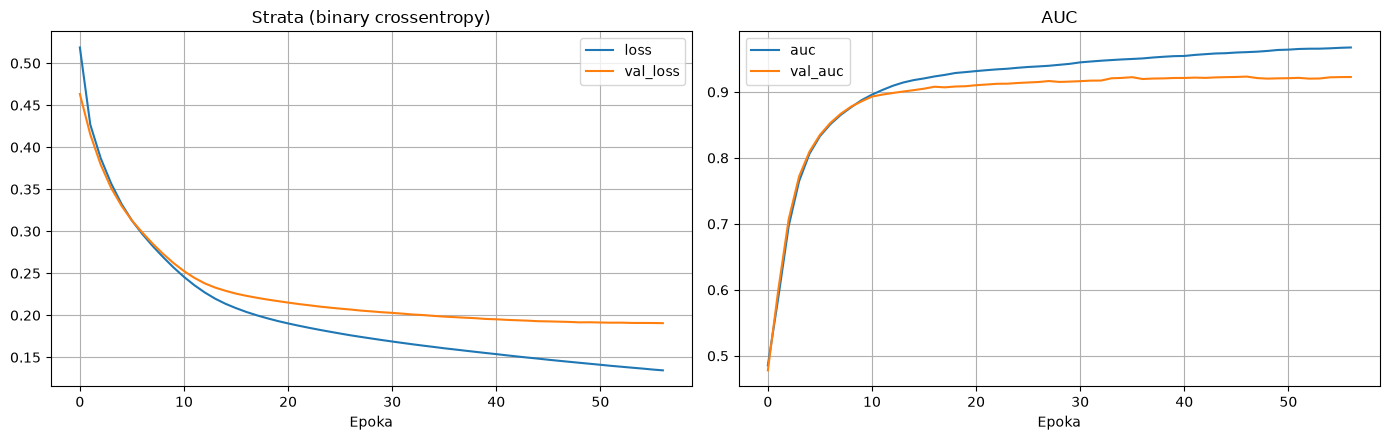

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
hist_nn[['loss', 'val_loss']].plot(ax=axes[0])
axes[0].set_title('Strata (binary crossentropy)')
hist_nn[['auc', 'val_auc']].plot(ax=axes[1])
axes[1].set_title('AUC')
for ax in axes:
    ax.set_xlabel('Epoka')
    ax.grid(True)
plt.tight_layout()
plt.show()

### Niezbalansowane klasy: `class_weight`

Sieć optymalizuje średnią stratę, więc rzadką klasę (odejścia) łatwo „przegłosować”. Podobnie jak w rozdziale 4.3, możemy zwiększyć wagę błędów na klasie mniejszościowej, przekazując `class_weight` do `fit()`.

In [7]:
weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print('Wagi klas:', {k: round(float(v), 2) for k, v in class_weight.items()})

model_cw, hist_cw = train_binary(class_weight=class_weight)

results.append(evaluate_binary('sieć neuronowa', y_test, model_nn.predict(X_test_s, verbose=0).ravel()))
results.append(evaluate_binary('sieć neuronowa + class_weight', y_test, model_cw.predict(X_test_s, verbose=0).ravel()))
pd.DataFrame(results).set_index('model').round(3)

Wagi klas: {0: 0.58, 1: 3.45}


,accuracy,precision,recall,ROC AUC
model,,,,
"baseline (zawsze ""zostanie"")",0.855,0.000,0.000,0.500
regresja logistyczna,0.859,0.537,0.227,0.818
las losowy,0.946,0.896,0.711,0.895
sieć neuronowa,0.915,0.744,0.629,0.892
sieć neuronowa + class_weight,0.882,0.569,0.763,0.884


Wnioski:
- sieć jest **znacznie lepsza od regresji logistycznej** pod względem ROC AUC i **zbliżona do lasu losowego** - tu zależności między cechami są nieliniowe, więc elastyczność sieci się opłaca,
- las losowy ma wciąż najwyższe ROC AUC; sieć wymagała skalowania, walidacji i doboru architektury, a nie dała przewagi - na danych tabelarycznych modele drzewiaste często pozostają mocnym wyborem,
- `class_weight` **zwiększa recall** (wykrywamy więcej odchodzących klientów) kosztem **precision** (więcej fałszywych alarmów) i accuracy. To kompromis do wyboru zgodnie z kosztami biznesowymi (rozdział 3.2: próg decyzyjny).

## 3. Klasyfikacja wieloklasowa: rodzaje wina

Zbiór `wine` to 178 win z trzech odmian winogron (klasy 0, 1, 2), opisanych 13 cechami chemicznymi (alkohol, kwasowość, fenole itd.). **Zmienna docelowa** to numer odmiany. Warstwa wyjściowa ma teraz **3 neurony z `softmax`** (po jednym na klasę), a funkcja straty to `sparse_categorical_crossentropy` - ta sama co w Fashion MNIST (etykiety jako liczby 0, 1, 2). Gdybyśmy zakodowali etykiety jako one-hot (`keras.utils.to_categorical`), użylibyśmy `categorical_crossentropy` i dostalibyśmy tę samą stratę.

Zbiór jest mały, więc na tym przykładzie dobrze widać **znaczenie skalowania cech**: porównamy sieć uczoną na surowych cechach i na standaryzowanych.

In [8]:
X_w, y_w = load_wine(return_X_y=True)
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_w, y_w, test_size=0.25, random_state=SEED, stratify=y_w
)
scaler_w = StandardScaler().fit(Xw_train)

print('Zakresy cech przed skalowaniem (min - max) dla trzech przykładowych kolumn:')
for j, name in [(0, 'alcohol'), (4, 'magnesium'), (12, 'proline')]:
    print(f'  {name:10s} {X_w[:, j].min():8.2f} - {X_w[:, j].max():8.2f}')
print('Baseline (najliczniejsza klasa):', round(np.bincount(yw_test).max() / len(yw_test), 3))

Zakresy cech przed skalowaniem (min - max) dla trzech przykładowych kolumn:
  alcohol       11.03 -    14.83
  magnesium     70.00 -   162.00
  proline      278.00 -  1680.00
Baseline (najliczniejsza klasa): 0.4


In [9]:
def train_wine(X_tr, X_te):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.layers.Input(shape=(13,)),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(3, activation='softmax'),
    ])
    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    model.fit(X_tr, yw_train, epochs=200, batch_size=16, validation_split=0.2,
              callbacks=[stop], verbose=0)
    return model.evaluate(X_te, yw_test, verbose=0)

rows = []
for name, (a, b) in {'sieć: surowe cechy': (Xw_train, Xw_test),
                     'sieć: standaryzacja': (scaler_w.transform(Xw_train), scaler_w.transform(Xw_test))}.items():
    loss, acc = train_wine(a, b)
    rows.append({'model': name, 'strata testowa': loss, 'accuracy testowe': acc})

logreg_w = LogisticRegression(max_iter=1000).fit(scaler_w.transform(Xw_train), yw_train)
rows.append({'model': 'regresja logistyczna (standaryzacja)', 'strata testowa': np.nan,
             'accuracy testowe': logreg_w.score(scaler_w.transform(Xw_test), yw_test)})
pd.DataFrame(rows).set_index('model').round(3)

,strata testowa,accuracy testowe
model,,
sieć: surowe cechy,0.311,0.911
sieć: standaryzacja,0.073,0.956
regresja logistyczna (standaryzacja),NaN,1.000


Cechy mają bardzo różne skale (np. `proline` rzędu setek i tysięcy, a `alcohol` rzędu kilkunastu), a **standaryzacja wyraźnie obniża stratę** sieci. Zbiór testowy ma tylko 45 win, więc dokładność zmienia się skokowo (jedna pomyłka to ponad 2 punkty procentowe) i nie ma sensu porównywać jej z dokładnością do ułamków procenta. Na tak małym, prostym zbiorze regresja logistyczna jest co najmniej tak dobra jak sieć - sieci potrzebują więcej danych.

## 4. Regresja: koszty ubezpieczenia

Zbiór `insurance` znamy z rozdziału 3.1. **Zmienna docelowa** `charges` to roczne koszty ubezpieczenia zdrowotnego w dolarach (od około 1100 do ponad 60 000). W regresji ostatnia warstwa ma **jeden neuron bez aktywacji** (może zwrócić dowolną liczbę), a stratą jest MSE.

Modelem bazowym jest przewidywanie średniej (`DummyRegressor`, $R^2 \approx 0$), a modelami porównawczymi - regresja liniowa i las losowy. Przygotowanie danych jak w 3.1 (kodowanie `get_dummies`) oraz standaryzacja cech.

In [10]:
ins = pd.read_csv('insurance.csv')
X_i = pd.get_dummies(ins.drop(columns='charges'), drop_first=True).astype('float32')
y_i = ins['charges']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_i, y_i, test_size=0.2, random_state=SEED)

scaler_x = StandardScaler().fit(Xi_train)
Xi_train_s, Xi_test_s = scaler_x.transform(Xi_train), scaler_x.transform(Xi_test)

reg_results = []
def evaluate_reg(name, pred):
    reg_results.append({'model': name, 'R2': r2_score(yi_test, pred), 'MAE ($)': mean_absolute_error(yi_test, pred)})

evaluate_reg('baseline (średnia)', DummyRegressor().fit(Xi_train, yi_train).predict(Xi_test))
evaluate_reg('regresja liniowa', LinearRegression().fit(Xi_train, yi_train).predict(Xi_test))
evaluate_reg('las losowy', RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED)
             .fit(Xi_train, yi_train).predict(Xi_test))
pd.DataFrame(reg_results).set_index('model').round(3)

,R2,MAE ($)
model,,
baseline (średnia),-0.001,9593.338
regresja liniowa,0.784,4181.195
las losowy,0.877,2475.042


### Sieć: skalowanie zmiennej docelowej

W regresji sieć zwraca liczby w skali zmiennej docelowej. Gdy `charges` mają wartości rzędu dziesiątek tysięcy, MSE jest rzędu setek milionów, a gradienty - ogromne, co psuje trening. Typowym rozwiązaniem jest **standaryzacja także zmiennej docelowej** (skaler dopasowany na zbiorze treningowym), a po predykcji - przekształcenie wyniku z powrotem na dolary (`inverse_transform`). Porównamy oba warianty.

In [11]:
scaler_y = StandardScaler().fit(yi_train.to_numpy().reshape(-1, 1))
yi_train_s = scaler_y.transform(yi_train.to_numpy().reshape(-1, 1)).ravel()

def build_regressor(n_features):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1),
    ])
    model.compile(loss='mse', optimizer='adam', metrics=['mae'])
    return model

# 1) y po standaryzacji, EarlyStopping na walidacji
keras.utils.set_random_seed(SEED)
reg_scaled = build_regressor(Xi_train_s.shape[1])
stop = keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)
hist_reg = reg_scaled.fit(Xi_train_s, yi_train_s, epochs=300, batch_size=32,
                          validation_split=0.2, callbacks=[stop], verbose=0)
pred_scaled = scaler_y.inverse_transform(reg_scaled.predict(Xi_test_s, verbose=0)).ravel()
evaluate_reg('sieć (y standaryzowane)', pred_scaled)

# 2) y w dolarach, bez skalowania, 100 epok
keras.utils.set_random_seed(SEED)
reg_raw = build_regressor(Xi_train_s.shape[1])
hist_raw = reg_raw.fit(Xi_train_s, yi_train, epochs=100, batch_size=32, validation_split=0.2, verbose=0)
evaluate_reg('sieć (y w dolarach)', reg_raw.predict(Xi_test_s, verbose=0).ravel())

print('Epok (y standaryzowane):', len(hist_reg.history['loss']))
print('Strata MSE w 1. i ostatniej epoce (y w dolarach): %.2e -> %.2e'
      % (hist_raw.history['loss'][0], hist_raw.history['loss'][-1]))
pd.DataFrame(reg_results).set_index('model').round(3)

Epok (y standaryzowane): 53
Strata MSE w 1. i ostatniej epoce (y w dolarach): 3.25e+08 -> 4.05e+07


,R2,MAE ($)
model,,
baseline (średnia),-0.001,9593.338
regresja liniowa,0.784,4181.195
las losowy,0.877,2475.042
sieć (y standaryzowane),0.860,2836.851
sieć (y w dolarach),0.759,4305.205


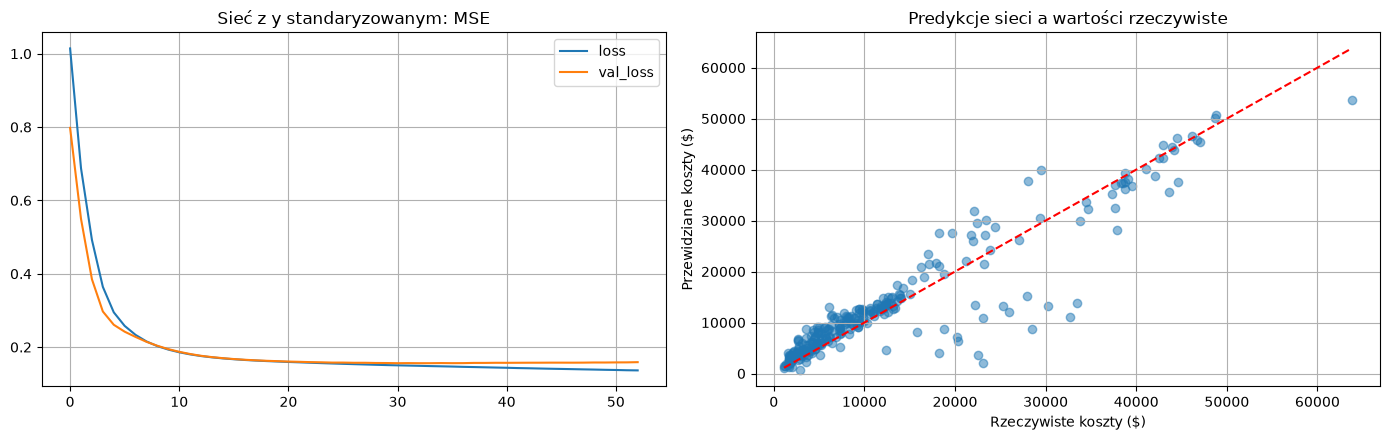

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pd.DataFrame(hist_reg.history)[['loss', 'val_loss']].plot(ax=axes[0])
axes[0].set_title('Sieć z y standaryzowanym: MSE')
axes[1].scatter(yi_test, pred_scaled, alpha=0.5)
axes[1].plot([yi_test.min(), yi_test.max()], [yi_test.min(), yi_test.max()], 'r--')
axes[1].set_xlabel('Rzeczywiste koszty ($)')
axes[1].set_ylabel('Przewidziane koszty ($)')
axes[1].set_title('Predykcje sieci a wartości rzeczywiste')
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()

- sieć ze standaryzowaną zmienną docelową jest **lepsza od regresji liniowej** (potrafi wychwycić interakcje, np. że palenie i otyłość razem podnoszą koszty bardziej niż osobno), ale **nie lepsza od lasu losowego**,
- ta sama sieć uczona na `charges` w dolarach wypada **wyraźnie gorzej**: strata na początku jest rzędu setek milionów i po 100 epokach wciąż jest bardzo wysoka,
- predykcje na wykresie leżą w większości wzdłuż przekątnej, ale dla wyższych kosztów rozrzut jest większy, a część obserwacji o kosztach rzędu 15-30 tys. dolarów sieć wyraźnie zaniżyła. Takie przypadki są rzadsze i trudniejsze do przewidzenia.

## 5. Podsumowanie

1. Dla sieci dane tabelaryczne trzeba **zakodować liczbowo i przeskalować** (skaler dopasowany na zbiorze treningowym). Dla regresji warto też przeskalować zmienną docelową.
2. Ostatnia warstwa i funkcja straty zależą od zadania: `sigmoid` + `binary_crossentropy` (binarna), `softmax` + `sparse_categorical_crossentropy` (wieloklasowa), jeden neuron bez aktywacji + `mse` (regresja).
3. Zawsze porównujemy sieć z **modelem bazowym** i **prostszymi modelami** (regresja, las losowy). Na danych tabelarycznych sieć bywa równa najlepszym modelom klasycznym, ale rzadko wyraźnie od nich lepsza, a jest trudniejsza w przygotowaniu.
4. Przy niezbalansowanych klasach `class_weight` pozwala zwiększyć recall kosztem precision.
5. `EarlyStopping` na zbiorze walidacyjnym chroni przed przeuczeniem i oszczędza czas.